# 다중 클래스 로지스틱 회귀

## 분류 대상과 입력

- 색상(hue) $x_1$과 길이/너비 $x_2$로 사과·오렌지·바나나 중 하나를 예측한다.
- 합성 데이터는 빨간 사과·오렌지·노란 바나나로 제한하며, 색상은 도 단위이다.

## 점수–확률–클래스 대응

### 클래스별 선형 점수

- 이 예제의 다중 클래스 모델은 다항 로지스틱 회귀(multinomial logistic regression)이다. 클래스 $k$마다 선형 점수(linear score)를 계산한다.

  $\displaystyle z_k=b_k+w_{k1}x_1+w_{k2}x_2.$

- 절편(intercept) $b_k$와 가중치(weight) $w_{k1},w_{k2}$가 같은 입력의 클래스별 기여를 정한다.

### softmax 확률

- softmax는 점수의 지수값을 전체 합으로 나누어 클래스별 확률을 계산한다.

  $\displaystyle p_k=\frac{e^{z_k}}{\sum_{j=1}^{3}e^{z_j}}, \qquad \sum_{k=1}^{3}p_k=1, \qquad \hat y=\underset{k}{\arg\max}\;p_k.$

- 확률의 합은 1이며, 가장 큰 확률의 클래스를 예측한다. 이 예제의 동률은 사과·오렌지·바나나 순서로 처리한다.
- 기본 입력인 색상 35°·길이/너비 1.8에서는 학습 후 바나나 약 76%, 오렌지 약 22%, 사과 약 2%로 예측한다.

  <img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-ai-convergence/main/07-1_Classification/assets/03_softmax_probabilities.png" alt="과일의 클래스별 점수와 확률" width="512" style="max-width:100%;height:auto;">

### 결정 경계

- 두 클래스 $a,b$의 확률은 $z_a=z_b$에서 같다. 그중 두 점수가 나머지 클래스 이상인 부분이 결정 경계(decision boundary)이다.
- 점수가 입력의 선형식이므로 경계는 직선 구간이다. 확률은 연속적으로 변하지만 경계를 넘으면 예측 클래스가 바뀐다.


## 손실과 매개변수 학습

### 원-핫 라벨

- 원-핫 인코딩(one-hot encoding)은 실제 클래스 위치만 1이고 나머지는 0인 벡터로 라벨을 표현하는 방법이다. 사과·오렌지·바나나 순서에서 오렌지는 $(0,1,0)$이다.
- 정답은 하나의 클래스이지만 예측 확률은 여러 클래스에 나뉠 수 있다.

### 교차 엔트로피

- 다중 클래스 교차 엔트로피(multiclass cross-entropy)는 과일 하나의 실제 클래스에 부여한 확률로 손실을 계산한다.

  $\displaystyle \ell=-\sum_{k=1}^{3}y_k\log p_k=-\log p_{\text{observed class}}.$

- $y_k$가 원-핫 라벨이므로 실제 클래스의 항만 남는다. 그 클래스의 확률이 낮을수록 손실이 커진다.
- 경사하강법(gradient descent)으로 평균 학습 손실(training loss)을 줄이며 계수를 학습한다. 표준화(standardization)와 계수 학습에는 학습 과일만 사용한다.

## 학습 단계와 입력 변화

- 초기 계수는 모두 0이고 각 확률은 $1/3$이다. 동률 규칙에 따라 배경 전체가 사과이며 결정 경계는 아직 없다.
- ‘Iteration’은 실제 갱신을 선택하고 ‘Fit model’은 2500회 결과를 적용한다. 과일의 위치는 고정되고 계수에 따라 예측 영역과 경계가 바뀐다.
- 확률·학습 손실·검증 정확도(validation accuracy)는 같은 계수로 계산한다. 검증 과일은 학습에 사용하지 않는다.
- 학습 손실이 줄어도 검증 과일의 분류가 매번 개선되지는 않으므로 검증 정확도는 단조롭게 증가하지 않는다.
- ‘Decision variable x1’은 색상(°), ‘Decision variable x2’는 길이/너비이다. 새 과일의 입력을 바꾸며, 학습한 계수는 그대로 둔다.


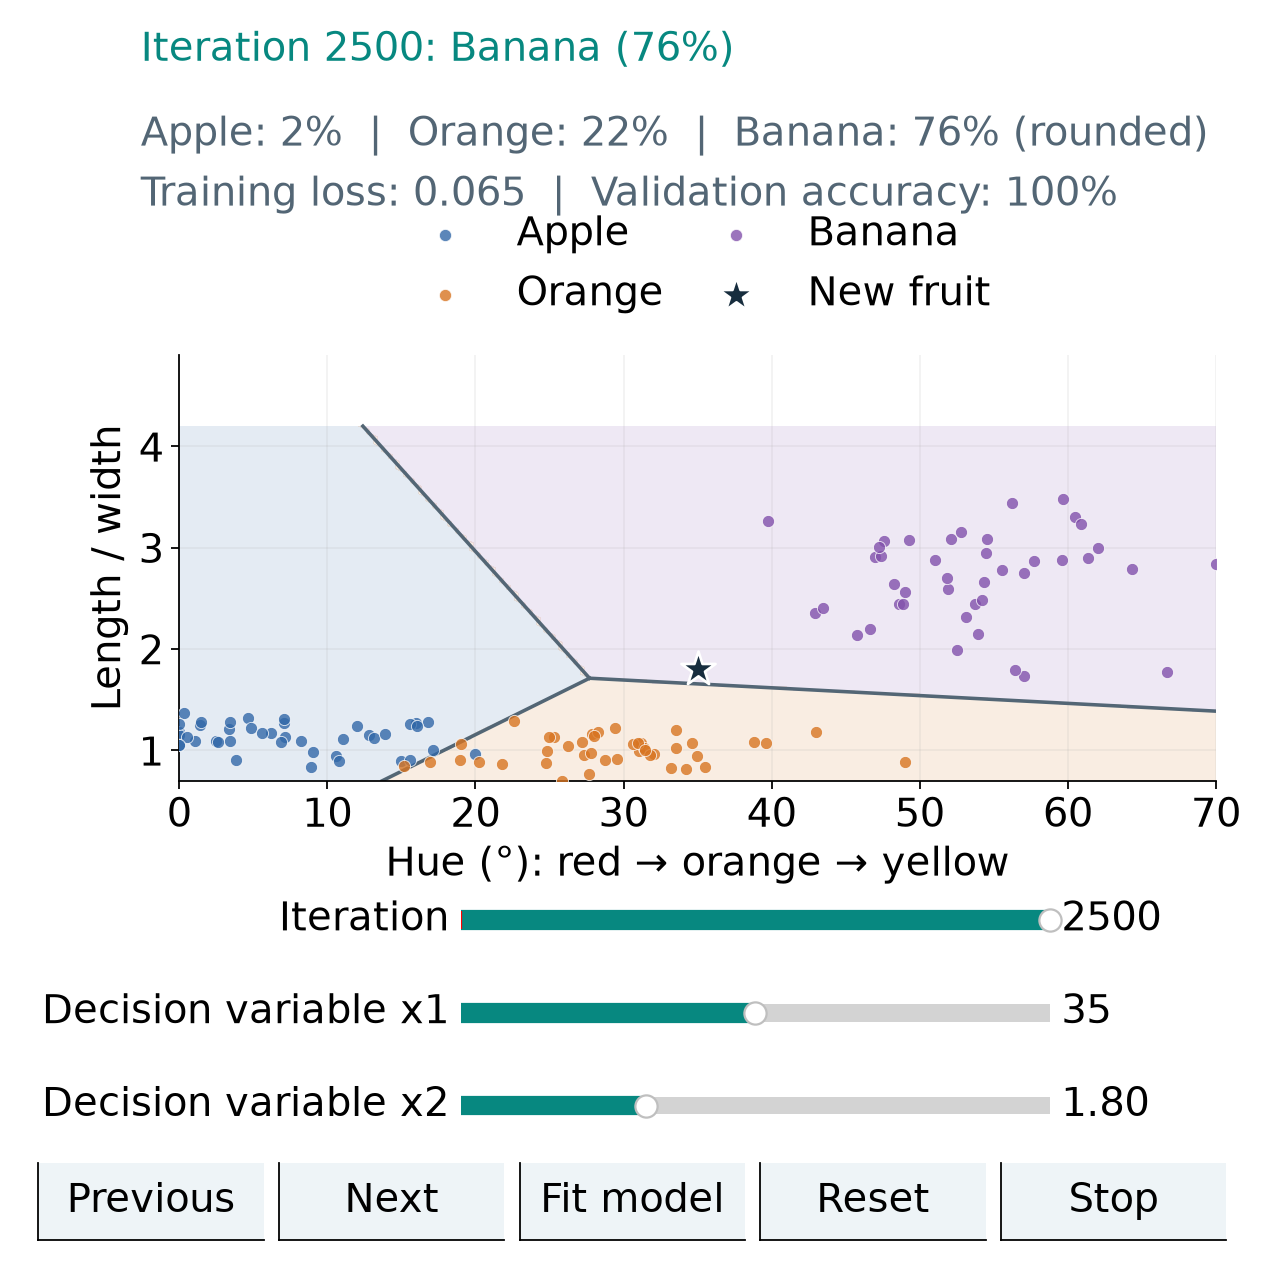

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLASSIFICATION_STATIC = os.environ.get("CLASSIFICATION_STATIC") == "1"
CLASSIFICATION_BROWSER = sys.platform == "emscripten"
if not CLASSIFICATION_STATIC and not CLASSIFICATION_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        shell.run_line_magic("matplotlib", "widget")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.size": 18, "axes.labelsize": 18,
    "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


def sigmoid(score):
    score = np.clip(np.asarray(score, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-score))


def softmax(scores):
    scores = np.asarray(scores, dtype=float)
    weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
    return weights / weights.sum(axis=-1, keepdims=True)


def binary_loss(labels, scores):
    return float(np.mean(np.logaddexp(0, scores) - labels * scores))


def classification_metrics(observed, predicted):
    observed, predicted = np.asarray(observed), np.asarray(predicted)
    tp = int(np.sum((observed == 1) & (predicted == 1)))
    tn = int(np.sum((observed == 0) & (predicted == 0)))
    fp = int(np.sum((observed == 0) & (predicted == 1)))
    fn = int(np.sum((observed == 1) & (predicted == 0)))
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn,
            "accuracy": (tp + tn) / len(observed),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan}


def percent(value):
    return "undefined" if not np.isfinite(value) else f"{value:.0%}"


for _previous_view in globals().get("_classification_views", {}).values():
    _previous_view.close()
_classification_views = {}


class ClassificationExplorer:

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=64)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=18, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=18, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 2.22 / height
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(18)
            slider.valtext.set_fontsize(18)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .94 / len(commands) - .012)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.03 + i * (width + .012), .25 / height, width, .48 / height]),
                            label,
                            color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(18)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())
        _classification_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        lower = ((self.tree_ax.get_position().y0 - .02) * height
                 if hasattr(self, "tree_ax") else max(0, self.ax.get_position().y0 * height - .78))
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=64, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            control.value = self.controls[key].val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="512px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=initial, min=low, max=high, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "180px"},
                                  layout=Layout(width="100%", max_width="512px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="512px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLASSIFICATION_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=512,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLASSIFICATION_BROWSER:
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()

    def close(self):
        self.stop()
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()


def make_messages(seed, count=240, spam_fraction=.35):
    rng = np.random.default_rng(seed)
    labels = np.zeros(count, dtype=int)
    labels[:round(count * spam_fraction)] = 1
    rng.shuffle(labels)
    phrases = rng.binomial(10, np.where(labels == 1, .53, .13))
    links = rng.binomial(4, np.where(labels == 1, .57, .13))
    return np.column_stack([phrases, links]), labels


def make_fruit(seed):
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 60)
    centers = np.array([[8, 1.15], [30, 1.05], [53, 2.8]])
    spreads = np.array([[8, .18], [7, .16], [7, .5]])
    values = centers[labels] + rng.normal(size=(len(labels), 2)) * spreads[labels]
    return np.clip(values, [0, .7], [70, 4.2]), labels

fruit, labels = make_fruit(71)
class_names = np.array(["Apple", "Orange", "Banana"])
class_colors = [BLUE, ORANGE, PURPLE]
train_id, validation_id = train_test_split(np.arange(len(labels)), test_size=.3,
                                         stratify=labels, random_state=71)
feature_mean, feature_scale = fruit[train_id].mean(axis=0), fruit[train_id].std(axis=0)


def fruit_features(values):
    values = np.atleast_2d(values)
    return np.column_stack([np.ones(len(values)), (values - feature_mean) / feature_scale])


train_features = fruit_features(fruit[train_id])
one_hot = np.eye(3)[labels[train_id]]
weights = np.zeros((3, 3))
weight_history = [weights.copy()]
for iteration in range(2500):
    probability = softmax(train_features @ weights)
    weights -= .15 * train_features.T @ (probability - one_hot) / len(train_id)
    weight_history.append(weights.copy())
weight_history = np.asarray(weight_history)
hue_grid, shape_grid = np.meshgrid(np.linspace(0, 70, 141), np.linspace(.7, 4.2, 101))
grid_features = fruit_features(np.c_[hue_grid.ravel(), shape_grid.ravel()])
validation_features = fruit_features(fruit[validation_id])


def fruit_boundaries(current_weights):
    raw = current_weights.copy()
    raw[1:] /= feature_scale[:, None]
    raw[0] -= feature_mean @ raw[1:]
    segments = []
    for first, second in [(0, 1), (0, 2), (1, 2)]:
        difference = raw[:, first] - raw[:, second]
        normal = difference[1:]
        norm_squared = float(normal @ normal)
        if norm_squared < 1e-24:
            continue
        origin = -difference[0] * normal / norm_squared
        direction = np.array([-normal[1], normal[0]])
        third = 3 - first - second
        constraints = [np.array([0., 1., 0.]), np.array([70., -1., 0.]),
                       np.array([-.7, 0., 1.]), np.array([4.2, 0., -1.]),
                       raw[:, first] - raw[:, third]]
        lower, upper = -np.inf, np.inf
        for constraint in constraints:
            offset = constraint[0] + constraint[1:] @ origin
            slope = constraint[1:] @ direction
            if abs(slope) < 1e-12:
                if offset < -1e-12:
                    lower, upper = 1., 0.
                    break
            elif slope > 0:
                lower = max(lower, -offset / slope)
            else:
                upper = min(upper, -offset / slope)
        if lower < upper:
            points = origin + np.array([lower, upper])[:, None] * direction
            segments.append((first, second, points))
    return segments


def render_fruit(view, iteration, hue, shape):
    current_weights = weight_history[int(iteration)]
    scores = (fruit_features([[hue, shape]]) @ current_weights)[0]
    probability = softmax(scores)
    predicted = int(probability.argmax())
    grid_probability = softmax(grid_features @ current_weights)
    regions = grid_probability.argmax(axis=1).reshape(hue_grid.shape)
    validation_probability = softmax(validation_features @ current_weights)
    validation_accuracy = float(np.mean(validation_probability.argmax(axis=1) == labels[validation_id]))
    training_scores = train_features @ current_weights
    loss = float(np.mean(np.logaddexp.reduce(training_scores, axis=1)
                         - training_scores[np.arange(len(train_id)), labels[train_id]]))
    boundaries = fruit_boundaries(current_weights)
    ax = view.ax
    ax.contourf(hue_grid, shape_grid, regions, levels=[-.5, .5, 1.5, 2.5],
                colors=class_colors, alpha=.13)
    for first, second, points in boundaries:
        ax.plot(points[:, 0], points[:, 1], color="#536675", linewidth=1.6, zorder=2)
    for index, (name, color) in enumerate(zip(class_names, class_colors)):
        selected = train_id[labels[train_id] == index]
        ax.scatter(fruit[selected, 0], fruit[selected, 1], color=color, s=30,
                   edgecolor="white", linewidth=.4, label=name, alpha=.8, zorder=3)
    ax.scatter([hue], [shape], color="#172d3e", marker="*", s=260,
               edgecolor="white", linewidth=1.2, zorder=5, label="New fruit")
    ax.set(xlim=(0, 70), ylim=(.7, 4.9), xlabel="Hue (°): red → orange → yellow",
           ylabel="Length / width")
    ax.legend(loc="lower center", bbox_to_anchor=(.5, 1.01),
              ncol=2, fontsize=18, columnspacing=.8, frameon=False)
    view.status.set_text(f"Iteration {int(iteration)}: {class_names[predicted]} ({probability[predicted]:.0%})")
    view.detail.set_text("  |  ".join(f"{name}: {p:.0%}" for name, p in zip(class_names, probability))
                         + f" (rounded)\nTraining loss: {loss:.3f}  |  Validation accuracy: {validation_accuracy:.0%}")
    return {"probability": probability, "scores": scores, "prediction": predicted,
            "query": np.array([hue, shape]), "weights": current_weights.copy(),
            "regions": regions, "boundaries": boundaries, "loss": loss,
            "validation_probability": validation_probability,
            "validation_accuracy": validation_accuracy}


fruit_demo = ClassificationExplorer("fruit", render_fruit, [
    ("iteration", "Iteration", 0, 2500, 0, 1, "%0.0f"),
    ("hue", "Decision variable x1", 0, 70, 35, 1, "%0.0f"),
    ("shape", "Decision variable x2", .7, 4.2, 1.8, .05, "%0.2f"),
], actions=[
    ("Previous", lambda view: view.set_values(iteration=max(0, int(view.controls["iteration"].val) - 1))),
    ("Next", lambda view: view.set_values(iteration=min(2500, int(view.controls["iteration"].val) + 1))),
    ("Fit model", lambda view: view.set_values(iteration=2500)),
])
if CLASSIFICATION_STATIC:
    fruit_demo.set_values(iteration=2500)
fruit_demo.start()


## 클래스 범위와 일반화 한계

- softmax는 정해진 클래스 중 하나를 고른다. 배를 입력해도 자동으로 ‘알 수 없음’이 되지 않으며, 높은 확률의 오분류도 가능하다.
- 숙성과 조명은 색상을 바꾼다. 초록 사과는 이 데이터의 범위 밖이며, 색과 모양이 겹치는 과일은 추가 특징이 필요할 수 있다.
- 검증 정확도는 별도로 나눈 합성 과일의 결과이다. 실제 적용 성능은 해당 환경을 대표하는 별도 시험 데이터로 평가해야 한다.
